# Clasificación de películas: árbol de decisión y red neuronal

*Notebook de referencia generado por Claude (ver sección 8).*

# 1. Introducción

El objetivo es clasificar películas en tres clases según su calidad: **Mala**, **Buena** y **Muy buena**.
Cada película se describe con atributos propios (género, presupuesto, ingresos, duración, popularidad,
productora) y con datos de sus tres intérpretes principales y su director.

Se desarrollan y comparan dos modelos:

- un **árbol de decisión** (Scikit-learn), y
- una **red neuronal artificial** (Keras).

El trabajo se organiza en: análisis exploratorio → preprocesamiento → experimentación con cada modelo →
comparación → predicciones sobre el conjunto de test.

# 2. Análisis exploratorio

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 30)

train = pd.read_csv('../data/movies_train.csv')
test = pd.read_csv('../data/movies_test_actualizado.csv')
print('train:', train.shape)
print('test: ', test.shape)

train: (12500, 25)
test:  (500, 25)


In [2]:
train.head()

,movieId,title,genre,class,belong_to_collection,budget,popularity,revenue,runtime,production_company_name,production_company_country,name_p1,popularity_p1,number_movies_p1,popularity_movies_p1,name_p2,popularity_p2,number_movies_p2,popularity_movies_p2,name_p3,popularity_p3,number_movies_p3,popularity_movies_p3,director_name,director_popularity
0,179111,Montparnasse Bienvenüe (2017),Other,Buena,False,0,10.146,0.0,97.0,ARTE,FR,Laetitia Dosch,7.5944,31,2.709677,Grégoire Monsaingeon,0.6600,8,2.250000,Souleymane Seye Ndiaye,1.2881,5,1.400000,Anaïs Sergeant,0.600
1,428,"Bronx Tale, A (1993)",Drama,Muy buena,False,10000000,69.960,17287898.0,121.0,HBO Films,NaN,Robert De Niro,45.8497,174,14.459770,Chazz Palminteri,15.0293,59,12.830508,Lillo Brancato,17.6631,22,5.272727,Robert De Niro,49.165
2,31698,Son of the Mask (2005),Adventure,Mala,True,84000000,39.318,NaN,94.0,New Line Cinema,NaN,Jamie Kennedy,12.2720,74,16.351351,Alan Cumming,11.1500,99,9.747475,Traylor Howard,15.7290,5,31.200000,Lawrence Guterman,2.423
3,189957,The Witness (1969),Comedy,Buena,False,0,4.108,0.0,103.0,MAFILM 1. Játékfilmstúdió,HU,Ferenc Kállai,0.8404,89,0.269663,Lajos Őze,1.8788,41,0.365854,Béla Both,0.6600,2,1.500000,Péter Bacsó,0.600
4,1226,"Quiet Man, The (1952)",Drama,Muy buena,False,1750000,31.434,3800000.0,129.0,Republic Pictures,NaN,John Wayne,12.2993,230,4.065217,Maureen O'Hara,15.3452,69,3.884058,Victor McLaglen,11.0032,123,1.268293,John Ford,8.346


In [3]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 12500 entries, 0 to 12499
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   movieId                     12500 non-null  int64  
 1   title                       12500 non-null  str    
 2   genre                       12472 non-null  str    
 3   class                       12500 non-null  str    
 4   belong_to_collection        12500 non-null  bool   
 5   budget                      12500 non-null  int64  
 6   popularity                  12500 non-null  float64
 7   revenue                     11855 non-null  float64
 8   runtime                     11264 non-null  float64
 9   production_company_name     12500 non-null  str    
 10  production_company_country  1285 non-null   str    
 11  name_p1                     12500 non-null  str    
 12  popularity_p1               12500 non-null  float64
 13  number_movies_p1            12500 non-null

## 2.1 Tipos de variables

### Identificador
`movieId`. Su dtype es `int64`, pero el número no mide nada: solo distingue películas. No se trata como numérica.

### Texto libre
`title`: un valor distinto por película; de él se puede extraer el año.

### Categóricas
- `genre`: género de la película.
- `production_company_name`: productora.
- `production_company_country`: país de la productora.
- `name_p1`, `name_p2`, `name_p3`: los tres intérpretes principales.
- `director_name`: director.

### Booleana
`belong_to_collection`: si la película pertenece a una saga o colección.

### Numéricas
- `budget`: presupuesto.
- `revenue`: ingresos.
- `runtime`: duración en minutos.
- `popularity`: popularidad de la película.
- `popularity_p1..3`: popularidad de cada intérprete.
- `number_movies_p1..3`: cantidad de películas de cada intérprete.
- `popularity_movies_p1..3`: popularidad promedio de las películas de cada intérprete.
- `director_popularity`: popularidad del director.

### Objetivo
`class`. Es la variable que el modelo tiene que aprender a predecir (Mala / Buena / Muy buena); todas las
demás columnas son atributos que se usan para predecirla.

## 2.2 Distribución de la clase

class
Mala         0.385
Buena        0.462
Muy buena    0.154
Name: count, dtype: float64


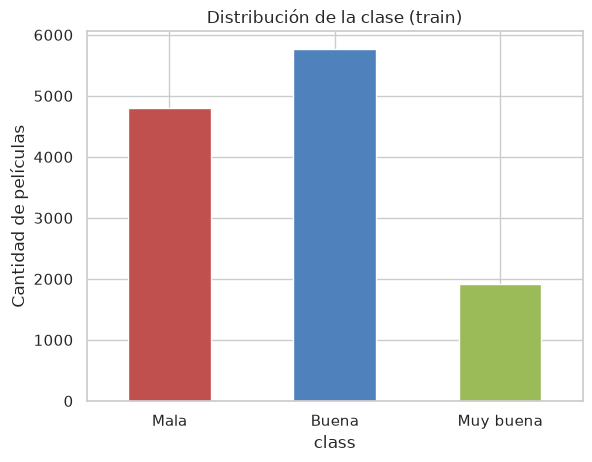

In [4]:
orden_clases = ['Mala', 'Buena', 'Muy buena']
conteo = train['class'].value_counts().reindex(orden_clases)
print((conteo / len(train)).round(3))
conteo.plot.bar(color=['#c0504d', '#4f81bd', '#9bbb59'], rot=0, title='Distribución de la clase (train)')
plt.ylabel('Cantidad de películas')
plt.show()

## 2.3 Valores faltantes

In [5]:
faltantes = pd.DataFrame({
    'faltantes': train.isna().sum(),
    'porcentaje': (train.isna().mean() * 100).round(1),
})
faltantes[faltantes['faltantes'] > 0].sort_values('faltantes', ascending=False)

,faltantes,porcentaje
production_company_country,11215,89.7
runtime,1236,9.9
revenue,645,5.2
genre,28,0.2
director_popularity,10,0.1


## 2.4 Ceros que significan "dato desconocido"

Una película no puede tener presupuesto 0 ni durar 0 minutos: esos ceros representan datos que no se conocen.

In [6]:
for col in ['budget', 'revenue', 'runtime']:
    print(f'{col:8s} = 0 en {(train[col] == 0).mean():.1%} de las películas')

budget   = 0 en 79.0% de las películas
revenue  = 0 en 76.3% de las películas
runtime  = 0 en 0.7% de las películas


## 2.5 Distribución de las variables numéricas

In [7]:
numericas = train.select_dtypes('number').columns.drop('movieId')
train[numericas].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
budget,12500.0,4092960.75,17031524.98,0.0,0.00,0.00,0.00,3.000000e+08
popularity,12500.0,12.58,29.41,0.6,2.54,5.64,12.87,7.234300e+02
revenue,11855.0,11537115.15,66512272.33,0.0,0.00,0.00,0.00,2.046240e+09
runtime,11264.0,98.34,25.29,0.0,88.00,95.00,107.00,5.660000e+02
popularity_p1,12500.0,11.35,13.85,0.6,2.94,6.93,14.29,2.069500e+02
number_movies_p1,12500.0,59.47,51.20,0.0,20.00,48.00,86.00,4.530000e+02
popularity_movies_p1,12500.0,8.14,14.89,0.0,1.77,3.79,9.00,2.634100e+02
popularity_p2,12500.0,9.22,12.08,0.6,2.20,5.46,11.88,2.470400e+02
number_movies_p2,12500.0,48.34,46.88,0.0,14.00,37.00,69.00,1.411000e+03
popularity_movies_p2,12500.0,6.99,12.18,0.0,1.62,3.38,7.77,4.354400e+02


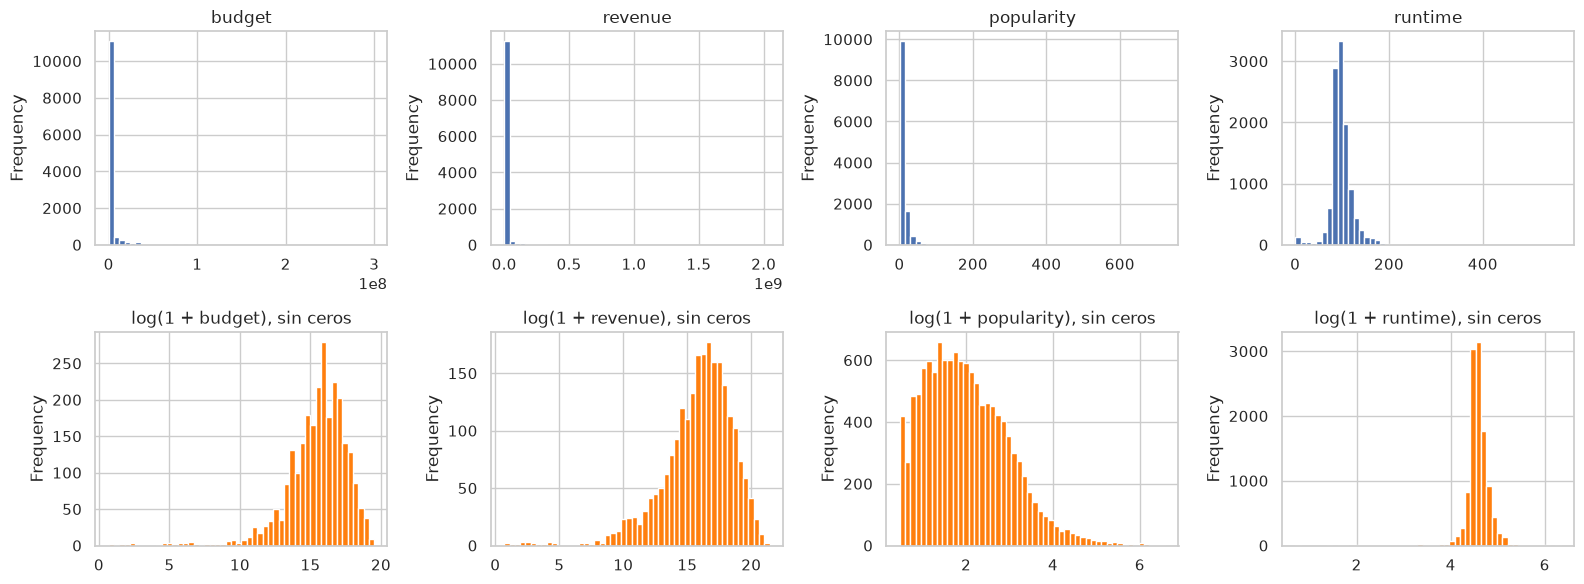

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for ax, col in zip(axes.flat, ['budget', 'revenue', 'popularity', 'runtime']):
    train[col].plot.hist(bins=50, ax=ax, title=col)
for ax, col in zip(axes.flat[4:], ['budget', 'revenue', 'popularity', 'runtime']):
    np.log1p(train[col].replace(0, np.nan)).plot.hist(bins=50, ax=ax, title=f'log(1 + {col}), sin ceros', color='tab:orange')
plt.tight_layout()
plt.show()

## 2.6 Cardinalidad de las variables categóricas

In [9]:
categoricas = ['genre', 'production_company_name', 'production_company_country',
               'name_p1', 'name_p2', 'name_p3', 'director_name']
train[categoricas].nunique().sort_values()

genre                             8
production_company_country       53
production_company_name        5402
director_name                  7689
name_p1                        7826
name_p2                        9420
name_p3                       10185
dtype: int64

## 2.7 Relación de los atributos con la clase

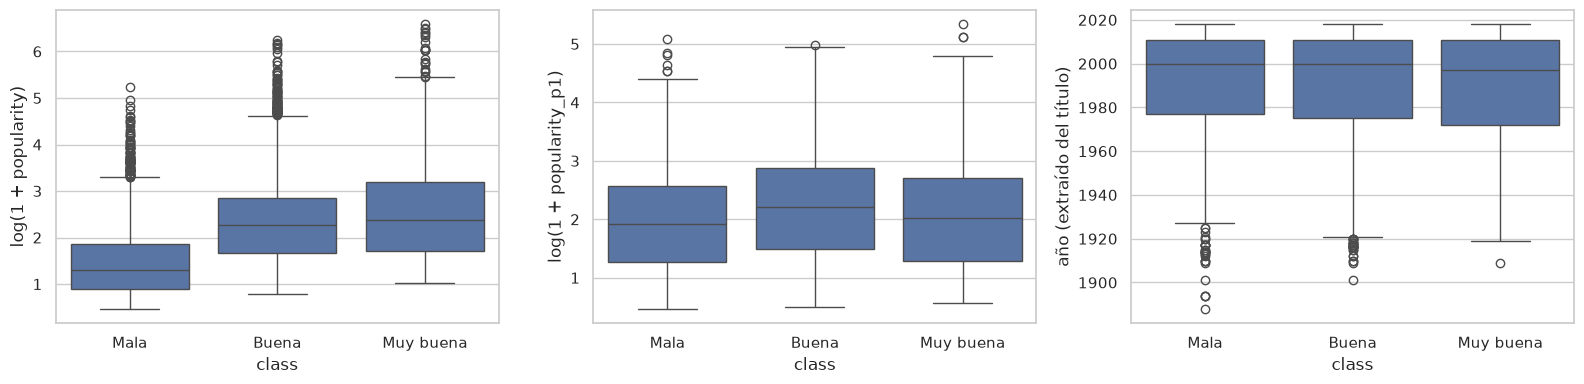

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.boxplot(data=train, x='class', y=np.log1p(train['popularity']), order=orden_clases, ax=axes[0])
axes[0].set_ylabel('log(1 + popularity)')
sns.boxplot(data=train, x='class', y=np.log1p(train['popularity_p1']), order=orden_clases, ax=axes[1])
axes[1].set_ylabel('log(1 + popularity_p1)')
anio = train['title'].str.extract(r'\((\d{4})\)\s*$')[0].astype(float)
sns.boxplot(data=train, x='class', y=anio, order=orden_clases, ax=axes[2])
axes[2].set_ylabel('año (extraído del título)')
plt.tight_layout()
plt.show()

In [11]:
pd.crosstab(train['genre'].fillna('Desconocido'), train['class'], normalize='index')[orden_clases].round(2)

class,Mala,Buena,Muy buena
genre,,,
Action,0.47,0.43,0.10
Adventure,0.41,0.45,0.14
Comedy,0.38,0.48,0.14
Crime,0.30,0.55,0.15
Desconocido,0.50,0.29,0.21
Documentary,0.19,0.46,0.35
Drama,0.27,0.53,0.20
Horror,0.69,0.28,0.02
Other,0.48,0.33,0.19


## 2.8 Conjunto de test

In [12]:
print('Mismas columnas que train:', list(test.columns) == list(train.columns))
print('Películas repetidas entre train y test:', train['movieId'].isin(test['movieId']).sum())
conteo_test = test['class'].value_counts().reindex(orden_clases)
pd.DataFrame({'cantidad': conteo_test,
              'proporción test': (conteo_test / len(test)).round(3),
              'proporción train': (conteo / len(train)).round(3)})

Mismas columnas que train: True
Películas repetidas entre train y test: 0


,cantidad,proporción test,proporción train
class,,,
Mala,192,0.384,0.385
Buena,231,0.462,0.462
Muy buena,77,0.154,0.154


## 2.9 Hallazgos

### Clase desbalanceada
*Muy buena* es la clase minoritaria (~15 %). La accuracy sola puede engañar, así que se usa también
**F1 macro**, que promedia el F1 de las tres clases por igual.

### Ceros disfrazados
`budget` (~79 %) y `revenue` (~76 %) valen 0 cuando el dato se desconoce. Hay que tratarlos como
faltantes y conservar la información de si el dato se conocía.

### Faltantes reales
- `production_company_country`: ~90 %.
- `runtime`: ~10 %.
- `revenue`, `genre` y `director_popularity`: pocos.

### Numéricas muy sesgadas
Montos y popularidades tienen colas largas; con `log(1 + x)` quedan distribuciones mucho más simétricas,
lo que conviene para la red neuronal.

### Alta cardinalidad
Productoras, intérpretes y directores tienen miles de valores distintos (casi uno por película).
Codificarlos con one-hot generaría miles de columnas casi vacías. Ya existen columnas numéricas que
resumen a esas personas (popularidad y cantidad de películas).

### Atributos prometedores
- `popularity`: separa claramente *Mala* de las otras dos clases.
- `genre`: es informativo; por ejemplo, *Horror* es mayoritariamente *Mala* y *Documentary* tiene la
  mayor proporción de *Muy buena*.
- Año (extraído del título): por sí solo separa poco, pero el árbol puede combinarlo con otros atributos.

### Test
Tiene las mismas columnas que train, incluida `class`, y la misma proporción de clases. Esa columna
**no** se usa para entrenar ni para elegir hiperparámetros.

# 3. Preprocesamiento

Las decisiones se derivan de los hallazgos del análisis exploratorio. Para evitar **fuga de datos**,
todo lo que se calcula a partir de los datos (medianas para imputar, columnas del one-hot, mínimos y
máximos del escalado) se obtiene **solo del conjunto de entrenamiento** y después se aplica igual a
validación y test.

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder

SEMILLA = 42

## 3.1 Ingeniería de atributos

Transformaciones fila a fila: no aprenden nada de los datos, así que no generan fuga.

### Año
Se extrae del título, por ejemplo `"Galaxy Quest (1999)"` → 1999.

### Ceros → faltante
En `budget`, `revenue` y `runtime` el 0 pasa a ser un faltante. Se agregan los indicadores
`budget_conocido` y `revenue_conocido`, porque que el dato se conozca puede ser informativo en sí mismo.

### País conocido
`pais_conocido` indica si se conoce el país de la productora. Con 90 % de faltantes no tiene sentido
imputar el país, pero sí registrar si existe.

### Colección
`belong_to_collection` se convierte a 0/1.

In [14]:
def crear_atributos(df):
    df = df.copy()
    df['year'] = df['title'].str.extract(r'\((\d{4})\)\s*$')[0].astype(float)
    for col in ['budget', 'revenue']:
        df[col] = df[col].replace(0, np.nan)
        df[f'{col}_conocido'] = df[col].notna().astype(int)
    df['runtime'] = df['runtime'].replace(0, np.nan)
    df['pais_conocido'] = df['production_company_country'].notna().astype(int)
    df['belong_to_collection'] = df['belong_to_collection'].astype(int)
    return df


X = crear_atributos(train.drop(columns='class'))
y = train['class']
X[['title', 'year', 'budget', 'budget_conocido', 'revenue', 'revenue_conocido', 'pais_conocido']].head()

,title,year,budget,budget_conocido,revenue,revenue_conocido,pais_conocido
0,Montparnasse Bienvenüe (2017),2017.0,NaN,0,NaN,0,1
1,"Bronx Tale, A (1993)",1993.0,10000000.0,1,17287898.0,1,0
2,Son of the Mask (2005),2005.0,84000000.0,1,NaN,0,0
3,The Witness (1969),1969.0,NaN,0,NaN,0,1
4,"Quiet Man, The (1952)",1952.0,1750000.0,1,3800000.0,1,0


## 3.2 Selección de columnas

### Columnas descartadas
- `movieId` y `title`: identificadores; el modelo solo podría memorizarlos.
- `production_company_name`, `production_company_country`, `name_p1..3` y `director_name`: alta
  cardinalidad.

Su información se conserva en parte mediante las columnas numéricas de popularidad y cantidad de
películas, y mediante `pais_conocido`.

### Codificación del género
`genre` se codifica con **one-hot**: tiene 8 valores sin un orden natural.

In [15]:
col_numericas = ['budget', 'revenue', 'popularity', 'runtime', 'year',
                 'popularity_p1', 'number_movies_p1', 'popularity_movies_p1',
                 'popularity_p2', 'number_movies_p2', 'popularity_movies_p2',
                 'popularity_p3', 'number_movies_p3', 'popularity_movies_p3',
                 'director_popularity']
col_binarias = ['belong_to_collection', 'budget_conocido', 'revenue_conocido', 'pais_conocido']
col_categoricas = ['genre']

## 3.3 División entrenamiento / validación

Se separa un 20 % del train como **validación** para comparar experimentos. La división es
**estratificada** para que ambos conjuntos tengan la misma proporción de clases.

In [16]:
X_ent, X_val, y_ent, y_val = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEMILLA)
print('entrenamiento:', X_ent.shape, ' validación:', X_val.shape)
pd.DataFrame({'entrenamiento': y_ent.value_counts(normalize=True),
              'validación': y_val.value_counts(normalize=True)}).round(3)

entrenamiento: (10000, 28)  validación: (2500, 28)


,entrenamiento,validación
class,,
Buena,0.462,0.462
Mala,0.385,0.385
Muy buena,0.154,0.154


## 3.4 Funciones de preprocesamiento

Los modelos tienen necesidades distintas:

| Paso | Árbol | Red neuronal |
|---|---|---|
| Imputar numéricas con la **mediana** (robusta a valores extremos) | ✔ | ✔ |
| Completar `genre` con "Desconocido" + one-hot | ✔ | ✔ |
| `log(1 + x)` en las numéricas con cola larga | — | ✔ |
| **Escalar** al intervalo [-1, 1] (`MinMaxScaler`) | — | ✔ |

El árbol decide comparando cada atributo contra un umbral, así que una transformación monótona
(logaritmo) o un cambio de escala no modifican los cortes posibles. La red neuronal, en cambio, se entrena
por descenso por gradiente: atributos con escalas muy distintas (presupuestos de millones contra
indicadores 0/1) hacen que el entrenamiento sea lento e inestable. El logaritmo va antes del escalado:
sin él, los pocos valores enormes de la cola definirían el máximo y el resto quedaría aplastado cerca
del -1.

Las dos funciones reciben primero el conjunto con el que se ajustan y después los demás conjuntos, a los
que solo se les aplica lo calculado con el primero.

In [17]:
col_cola_larga = [c for c in col_numericas if c != 'year']


def preprocesar(X_ajuste, *otros):
    medianas = X_ajuste[col_numericas].median()
    resultado = []
    for df in (X_ajuste, *otros):
        df = df[col_numericas + col_binarias + col_categoricas].copy()
        df[col_numericas] = df[col_numericas].fillna(medianas)
        df['genre'] = df['genre'].fillna('Desconocido')
        resultado.append(pd.get_dummies(df, columns=['genre'], dtype=int))
    # Mismas columnas que el conjunto de ajuste: un género que no aparece en él se descarta,
    # y uno que falta en otro conjunto queda como columna de ceros.
    columnas = resultado[0].columns
    return [df.reindex(columns=columnas, fill_value=0) for df in resultado]


def escalar(A_ajuste, *otros):
    def con_log(A):
        A = A.copy()
        A[col_cola_larga] = np.log1p(A[col_cola_larga])
        return A

    escalador = MinMaxScaler(feature_range=(-1, 1)).fit(con_log(A_ajuste))
    return [escalador.transform(con_log(A)).astype('float32') for A in (A_ajuste, *otros)]

## 3.5 Codificación de la clase

Scikit-learn acepta las etiquetas como texto, pero la red neuronal necesita números: cada clase se
representa como un vector **one-hot** de 3 valores, que tiene la misma forma que la salida de la red. Se
fija el orden de las categorías (*Mala*, *Buena*, *Muy buena*) para poder volver a las etiquetas al final.

In [18]:
codificador_clase = OneHotEncoder(categories=[orden_clases], sparse_output=False)
codificador_clase.fit(y.to_numpy().reshape(-1, 1))


def a_one_hot(etiquetas):
    return codificador_clase.transform(np.asarray(etiquetas).reshape(-1, 1))


def a_etiquetas(probabilidades):
    return np.array(orden_clases)[probabilidades.argmax(axis=1)]


pd.DataFrame(a_one_hot(orden_clases), index=orden_clases, columns=orden_clases)

,Mala,Buena,Muy buena
Mala,1.0,0.0,0.0
Buena,0.0,1.0,0.0
Muy buena,0.0,0.0,1.0


# 4. Árbol de decisión

In [19]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

Xa_ent, Xa_val = preprocesar(X_ent, X_val)
print('atributos:', Xa_ent.shape[1])


def evaluar(pred_ent, pred_val, y_e=y_ent, y_v=y_val):
    return {
        'acc_ent': accuracy_score(y_e, pred_ent),
        'acc_val': accuracy_score(y_v, pred_val),
        'f1_ent': f1_score(y_e, pred_ent, average='macro'),
        'f1_val': f1_score(y_v, pred_val, average='macro'),
    }


def entrenar_arbol(**params):
    return DecisionTreeClassifier(random_state=SEMILLA, **params).fit(Xa_ent, y_ent)


experimentos_arbol = []

def experimento_arbol(nombre, **params):
    modelo = entrenar_arbol(**params)
    resultado = {'experimento': nombre, **evaluar(modelo.predict(Xa_ent), modelo.predict(Xa_val))}
    experimentos_arbol.append(resultado)
    return modelo, resultado

atributos: 28


## 4.1 Línea base

Un clasificador que siempre predice la clase más frecuente del entrenamiento. Cualquier modelo útil tiene
que superarlo.

In [20]:
mayoritaria = y_ent.value_counts().idxmax()
pred_base_val = np.full(len(y_val), mayoritaria)
linea_base = {'experimento': f'Línea base (siempre {mayoritaria})',
              **evaluar(np.full(len(y_ent), mayoritaria), pred_base_val)}
pd.DataFrame([linea_base]).round(3)

,experimento,acc_ent,acc_val,f1_ent,f1_val
0,Línea base (siempre Buena),0.462,0.462,0.211,0.211


## 4.2 Experimento 1: árbol con parámetros por defecto

Sin restricciones, el árbol crece hasta clasificar perfectamente cada ejemplo de entrenamiento.

In [21]:
arbol_defecto, res = experimento_arbol('E1: por defecto')
print('profundidad alcanzada:', arbol_defecto.get_depth(), ' hojas:', arbol_defecto.get_n_leaves())
pd.DataFrame([res]).round(3)

profundidad alcanzada: 30  hojas: 1780


,experimento,acc_ent,acc_val,f1_ent,f1_val
0,E1: por defecto,1.0,0.662,1.0,0.624


## 4.3 Experimento 2: limitar la profundidad (`max_depth`)

Limitar la profundidad es la forma más directa de controlar el sobreajuste: menos niveles = reglas más generales.

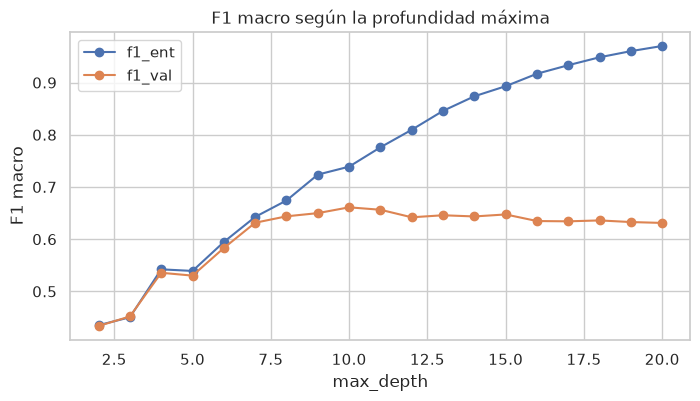

Mejor profundidad en validación: 10


,experimento,acc_ent,acc_val,f1_ent,f1_val
0,E2: max_depth=10,0.789,0.721,0.739,0.661


In [22]:
profundidades = range(2, 21)
barrido = []
for d in profundidades:
    modelo = entrenar_arbol(max_depth=d)
    barrido.append({'max_depth': d, **evaluar(modelo.predict(Xa_ent), modelo.predict(Xa_val))})
barrido_prof = pd.DataFrame(barrido)

ax = barrido_prof.plot(x='max_depth', y=['f1_ent', 'f1_val'], marker='o', figsize=(8, 4),
                       title='F1 macro según la profundidad máxima')
ax.set_ylabel('F1 macro')
plt.show()

mejor_prof = int(barrido_prof.loc[barrido_prof['f1_val'].idxmax(), 'max_depth'])
print('Mejor profundidad en validación:', mejor_prof)
_, res = experimento_arbol(f'E2: max_depth={mejor_prof}', max_depth=mejor_prof)
pd.DataFrame([res]).round(3)

## 4.4 Experimento 3: mínimo de ejemplos por hoja (`min_samples_leaf`)

Exigir un mínimo de ejemplos en cada hoja evita reglas que se apoyan en muy pocos casos.

In [23]:
barrido = []
for hoja in [1, 5, 10, 20, 50, 100]:
    modelo = entrenar_arbol(max_depth=mejor_prof, min_samples_leaf=hoja)
    barrido.append({'min_samples_leaf': hoja, **evaluar(modelo.predict(Xa_ent), modelo.predict(Xa_val))})
barrido_hoja = pd.DataFrame(barrido)
mejor_hoja = int(barrido_hoja.loc[barrido_hoja['f1_val'].idxmax(), 'min_samples_leaf'])
_, res = experimento_arbol(f'E3: max_depth={mejor_prof}, min_samples_leaf={mejor_hoja}',
                           max_depth=mejor_prof, min_samples_leaf=mejor_hoja)
barrido_hoja.round(3)

,min_samples_leaf,acc_ent,acc_val,f1_ent,f1_val
0,1,0.789,0.721,0.739,0.661
1,5,0.777,0.718,0.723,0.657
2,10,0.767,0.720,0.709,0.661
3,20,0.753,0.722,0.692,0.664
4,50,0.730,0.718,0.678,0.666
5,100,0.697,0.684,0.622,0.606


## 4.5 Experimento 4: criterio de división y peso de las clases

- `criterion`: medida de impureza para elegir los cortes (**Gini** o **entropía**).
- `class_weight='balanced'`: da más peso a los errores en las clases minoritarias, para que el árbol
  no ignore *Muy buena*.

In [24]:
filas = []
for criterio in ['gini', 'entropy']:
    for pesos in [None, 'balanced']:
        nombre = f'E4: {criterio}, class_weight={pesos}'
        _, res = experimento_arbol(nombre, max_depth=mejor_prof, min_samples_leaf=mejor_hoja,
                                   criterion=criterio, class_weight=pesos)
        filas.append({'criterion': criterio, 'class_weight': pesos, **res})
barrido_e4 = pd.DataFrame(filas)
mejor_e4 = filas[barrido_e4['f1_val'].idxmax()]
mejor_criterio, mejores_pesos = mejor_e4['criterion'], mejor_e4['class_weight']
print('Mejor combinación:', mejor_criterio, mejores_pesos)
barrido_e4.drop(columns=['criterion', 'class_weight']).round(3)

Mejor combinación: gini None


,experimento,acc_ent,acc_val,f1_ent,f1_val
0,"E4: gini, class_weight=None",0.730,0.718,0.678,0.666
1,"E4: gini, class_weight=balanced",0.677,0.641,0.658,0.614
2,"E4: entropy, class_weight=None",0.724,0.715,0.664,0.653
3,"E4: entropy, class_weight=balanced",0.670,0.648,0.650,0.621


## 4.6 Experimento 5: barrido conjunto de profundidad y mínimo por hoja

Los experimentos 2 y 3 ajustan un parámetro por vez: primero se fija la profundidad y recién después se
busca el mínimo por hoja. Pero la mejor profundidad puede cambiar cuando se exige un mínimo por hoja. Acá
se prueban **todas las combinaciones** de los dos, con el criterio y los pesos elegidos en el experimento 4.

In [25]:
barrido = []
for d in [6, 8, 10, 12, 15]:
    for hoja in [1, 5, 10, 20, 50]:
        modelo = entrenar_arbol(max_depth=d, min_samples_leaf=hoja,
                                criterion=mejor_criterio, class_weight=mejores_pesos)
        barrido.append({'max_depth': d, 'min_samples_leaf': hoja,
                        **evaluar(modelo.predict(Xa_ent), modelo.predict(Xa_val))})
barrido_conjunto = pd.DataFrame(barrido)

mejor_comb = barrido_conjunto.loc[barrido_conjunto['f1_val'].idxmax()]
mejores_params_arbol = dict(max_depth=int(mejor_comb['max_depth']),
                            min_samples_leaf=int(mejor_comb['min_samples_leaf']),
                            criterion=mejor_criterio, class_weight=mejores_pesos)
print('Mejores parámetros:', mejores_params_arbol)
mejor_arbol, res = experimento_arbol(
    f"E5: max_depth={mejores_params_arbol['max_depth']}, "
    f"min_samples_leaf={mejores_params_arbol['min_samples_leaf']}", **mejores_params_arbol)

# F1 macro en validación para cada combinación
barrido_conjunto.pivot(index='max_depth', columns='min_samples_leaf', values='f1_val').round(3)

Mejores parámetros: {'max_depth': 10, 'min_samples_leaf': 50, 'criterion': 'gini', 'class_weight': None}


min_samples_leaf,1,5,10,20,50
max_depth,,,,,
6,0.583,0.583,0.583,0.588,0.592
8,0.644,0.640,0.642,0.636,0.661
10,0.661,0.657,0.661,0.664,0.666
12,0.642,0.652,0.660,0.652,0.665
15,0.647,0.653,0.656,0.653,0.663


## 4.7 Resumen de experimentos del árbol

In [26]:
resumen_arbol = pd.DataFrame([linea_base] + experimentos_arbol).round(3)
resumen_arbol

,experimento,acc_ent,acc_val,f1_ent,f1_val
0,Línea base (siempre Buena),0.462,0.462,0.211,0.211
1,E1: por defecto,1.000,0.662,1.000,0.624
2,E2: max_depth=10,0.789,0.721,0.739,0.661
3,"E3: max_depth=10, min_samples_leaf=50",0.730,0.718,0.678,0.666
4,"E4: gini, class_weight=None",0.730,0.718,0.678,0.666
5,"E4: gini, class_weight=balanced",0.677,0.641,0.658,0.614
6,"E4: entropy, class_weight=None",0.724,0.715,0.664,0.653
7,"E4: entropy, class_weight=balanced",0.670,0.648,0.650,0.621
8,"E5: max_depth=10, min_samples_leaf=50",0.730,0.718,0.678,0.666


Lectura de la tabla, experimento por experimento.

### E1: parámetros por defecto
El árbol crece hasta 30 niveles y 1780 hojas y acierta el 100 % del entrenamiento, pero solo el 66 % de
validación: **sobreajuste**, memoriza en lugar de generalizar.

### E2: `max_depth`
La profundidad 10 maximiza el F1 macro en validación (0.624 → 0.661). En el gráfico se ve que con más
profundidad el F1 de entrenamiento sigue subiendo mientras el de validación cae.

### E3: `min_samples_leaf`
Exigir 50 ejemplos por hoja mejora apenas el F1 de validación (0.666) y achica la brecha entre
entrenamiento y validación: el modelo es más simple.

### E4: criterio y pesos
Gini y entropía dan resultados parecidos. `class_weight='balanced'` **empeora** el F1 macro (0.614): el
recall de *Muy buena* sube de 0.40 a 0.65, pero su precisión cae de 0.65 a 0.37 y el recall de *Buena*
baja de 0.76 a 0.52.

### E5: barrido conjunto
De las 25 combinaciones, la mejor vuelve a ser profundidad 10 con 50 ejemplos por hoja (F1 macro 0.666):
ajustar un parámetro por vez ya había encontrado el óptimo. La tabla también muestra que las
profundidades 10 a 15 con 50 por hoja dan resultados casi iguales (0.663 a 0.666), así que el resultado
no depende de un valor exacto. Ese es el árbol elegido: 113 hojas, contra las 1780 de E1.

## 4.8 Evaluación del mejor árbol

              precision    recall  f1-score   support

        Mala      0.754     0.789     0.771       962
       Buena      0.702     0.764     0.732      1154
   Muy buena      0.653     0.401     0.497       384

    accuracy                          0.718      2500
   macro avg      0.703     0.651     0.666      2500
weighted avg      0.714     0.718     0.711      2500



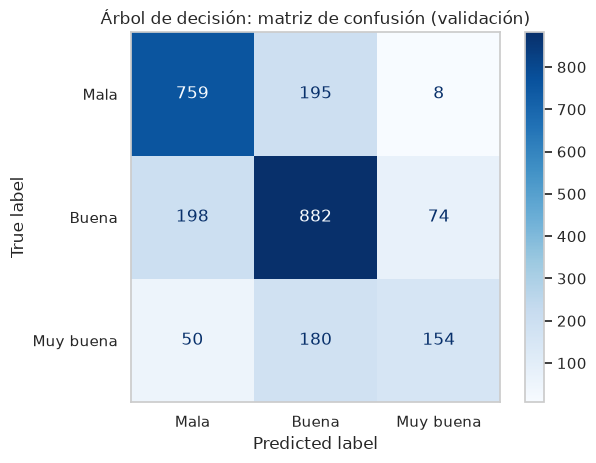

In [27]:
pred_val_arbol = mejor_arbol.predict(Xa_val)
print(classification_report(y_val, pred_val_arbol, labels=orden_clases, digits=3))
ConfusionMatrixDisplay.from_predictions(y_val, pred_val_arbol, labels=orden_clases, cmap='Blues')
plt.title('Árbol de decisión: matriz de confusión (validación)')
plt.grid(False)
plt.show()

## 4.9 Interpretación

Una ventaja del árbol es que sus decisiones se pueden leer. Se muestran los primeros niveles y la
importancia de cada atributo (cuánto reduce la impureza en total).

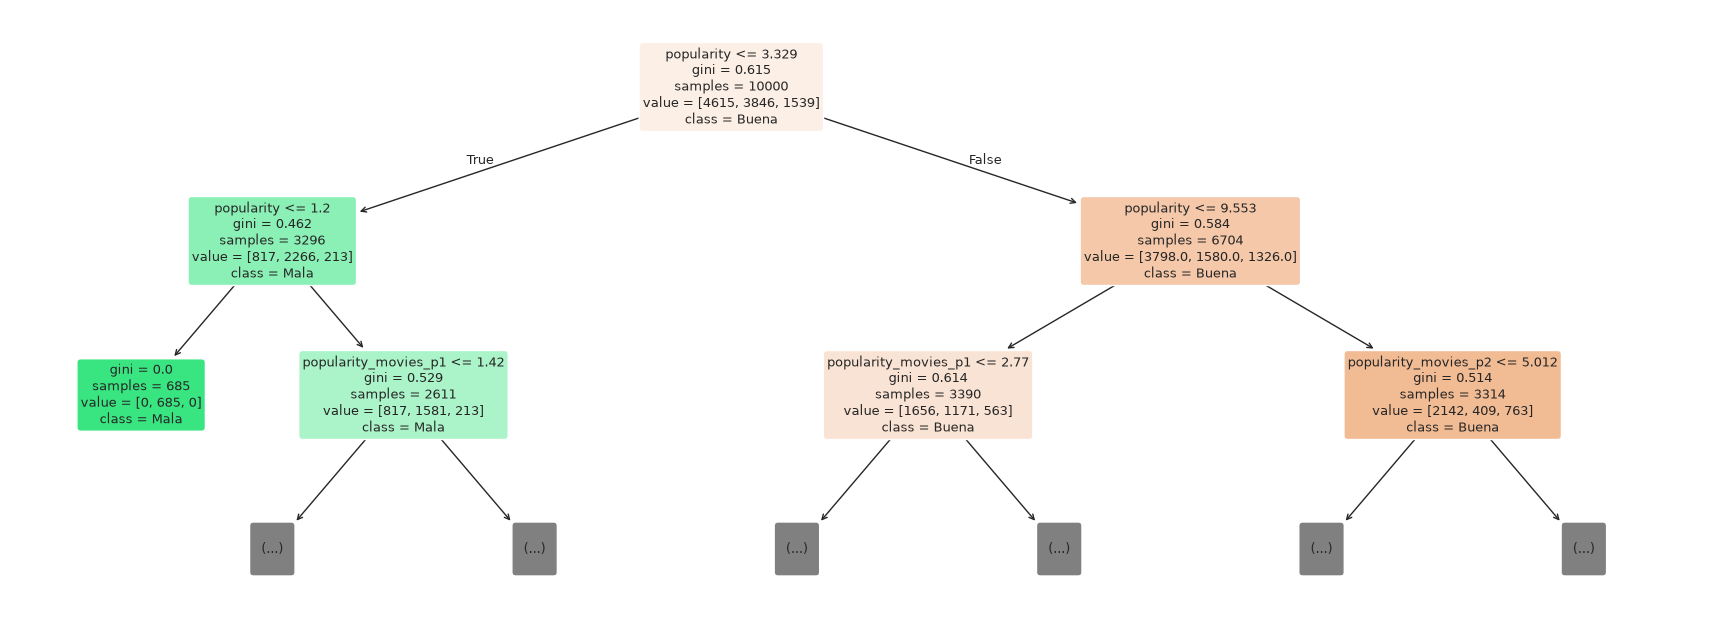

In [28]:
nombres_atributos = Xa_ent.columns.tolist()
plt.figure(figsize=(22, 8))
plot_tree(mejor_arbol, max_depth=2, feature_names=nombres_atributos,
          class_names=mejor_arbol.classes_, filled=True, rounded=True, fontsize=9)
plt.show()

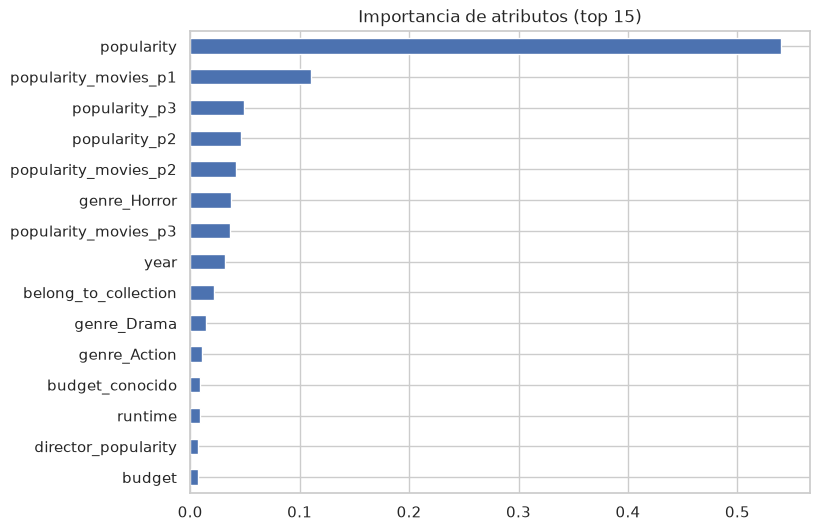

In [29]:
importancias = pd.Series(mejor_arbol.feature_importances_, index=nombres_atributos)
importancias.sort_values().tail(15).plot.barh(figsize=(8, 6), title='Importancia de atributos (top 15)')
plt.show()

# 5. Red neuronal

La red usa el preprocesamiento con logaritmo y escalado. Del conjunto de entrenamiento se separa además un
15 % para **early stopping**, de modo que el conjunto de validación se use solo para comparar experimentos
(igual que con el árbol).

In [30]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import keras
import tensorflow as tf

keras.utils.set_random_seed(SEMILLA)
tf.config.experimental.enable_op_determinism()

X_red, X_es, y_red, y_es = train_test_split(X_ent, y_ent, test_size=0.15, stratify=y_ent, random_state=SEMILLA)

Xr_red, Xr_es, Xr_val = escalar(*preprocesar(X_red, X_es, X_val))
Yr_red, Yr_es = a_one_hot(y_red), a_one_hot(y_es)
print('atributos de entrada:', Xr_red.shape[1])

I0000 00:00:1792171285.732302  932545 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


atributos de entrada: 28


I0000 00:00:1792171286.788069  932545 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


## 5.1 Funciones auxiliares

### Arquitectura
Capas densas con activación **ReLU**, opcionalmente seguidas de **Dropout**. La capa de salida tiene
3 neuronas con **softmax** (una probabilidad por clase).

### Entrenamiento
Optimizador **Adam** y pérdida `categorical_crossentropy` (clases como vectores one-hot).

### Early stopping
Corta el entrenamiento cuando la pérdida en el conjunto de early stopping deja de mejorar durante
15 épocas y restaura los mejores pesos.

In [31]:
def construir_rna(capas, dropout=0.0, tasa_aprendizaje=1e-3):
    keras.utils.set_random_seed(SEMILLA)
    modelo = keras.Sequential([keras.Input(shape=(Xr_red.shape[1],))])
    for neuronas in capas:
        modelo.add(keras.layers.Dense(neuronas, activation='relu'))
        if dropout:
            modelo.add(keras.layers.Dropout(dropout))
    modelo.add(keras.layers.Dense(len(orden_clases), activation='softmax'))
    modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=tasa_aprendizaje),
                   loss='categorical_crossentropy', metrics=['accuracy'])
    return modelo


def graficar_curvas(historia, titulo):
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
    for ax, metrica in zip(axes, ['loss', 'accuracy']):
        ax.plot(historia.history[metrica], label='entrenamiento')
        ax.plot(historia.history[f'val_{metrica}'], label='early stopping')
        ax.set_title(f'{titulo}: {metrica}')
        ax.set_xlabel('época')
        ax.legend()
    plt.tight_layout()
    plt.show()


experimentos_rna = []
modelos_rna = []

def experimento_rna(nombre, capas, dropout=0.0, tasa_aprendizaje=1e-3, batch_size=32,
                    epocas=300, early_stopping=True, pesos_clases=None):
    modelo = construir_rna(capas, dropout, tasa_aprendizaje)
    callbacks = [keras.callbacks.EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)] \
        if early_stopping else []
    historia = modelo.fit(Xr_red, Yr_red, validation_data=(Xr_es, Yr_es), epochs=epocas, batch_size=batch_size,
                          class_weight=pesos_clases, callbacks=callbacks, verbose=0)
    mejor_epoca = int(np.argmin(historia.history['val_loss'])) + 1 if early_stopping else epocas
    pred_e = a_etiquetas(modelo.predict(Xr_red, verbose=0))
    pred_v = a_etiquetas(modelo.predict(Xr_val, verbose=0))
    resultado = {
        'experimento': nombre, 'capas': str(capas), 'dropout': dropout, 'lr': f'{tasa_aprendizaje:g}',
        'batch': batch_size, 'pesos': 'balanced' if pesos_clases else '-',
        'épocas': len(historia.history['loss']), 'mejor_época': mejor_epoca,
        **evaluar(pred_e, pred_v, y_e=y_red),
    }
    experimentos_rna.append(resultado)
    modelos_rna.append((modelo, dict(capas=capas, dropout=dropout, tasa_aprendizaje=tasa_aprendizaje,
                                     batch_size=batch_size, pesos_clases=pesos_clases)))
    graficar_curvas(historia, nombre)
    return modelo, resultado

## 5.2 Experimento 1: red chica sin early stopping

Una capa oculta de 16 neuronas, 200 épocas fijas. Sirve de referencia y para ver qué pasa si se entrena
demasiado tiempo.

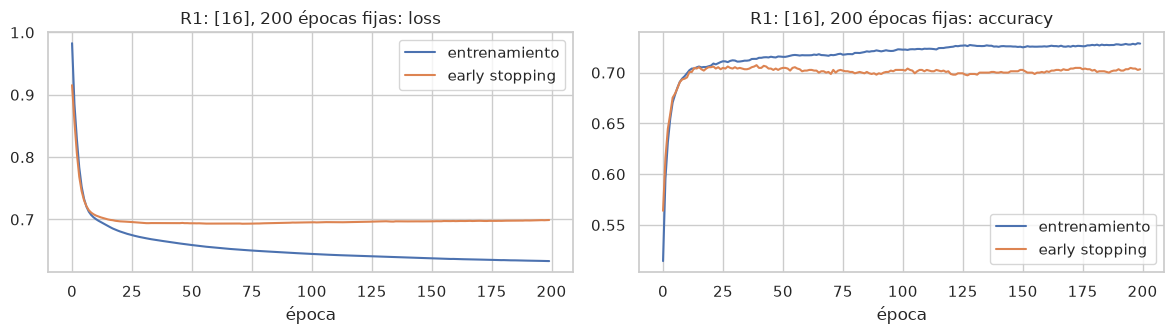

,experimento,capas,dropout,lr,batch,pesos,épocas,mejor_época,acc_ent,acc_val,f1_ent,f1_val
0,"R1: [16], 200 épocas fijas",[16],0.0,0.001,32,-,200,200,0.73,0.708,0.668,0.633


In [32]:
_, res = experimento_rna('R1: [16], 200 épocas fijas', [16], epocas=200, early_stopping=False)
pd.DataFrame([res]).round(3)

## 5.3 Experimento 2: misma red con early stopping

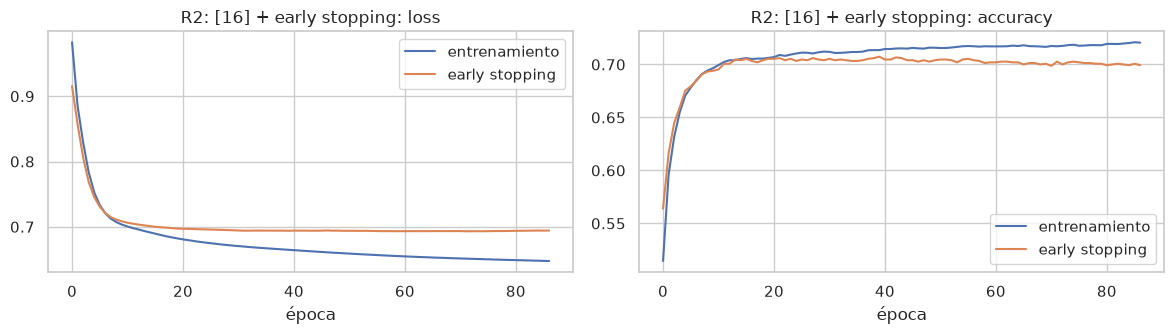

,experimento,capas,dropout,lr,batch,pesos,épocas,mejor_época,acc_ent,acc_val,f1_ent,f1_val
0,R2: [16] + early stopping,[16],0.0,0.001,32,-,87,72,0.722,0.707,0.653,0.627


In [33]:
_, res = experimento_rna('R2: [16] + early stopping', [16])
pd.DataFrame([res]).round(3)

## 5.4 Experimento 3: más capacidad

Dos capas ocultas (64 y 32 neuronas): la red puede aprender relaciones más complejas, pero también
sobreajustar más rápido.

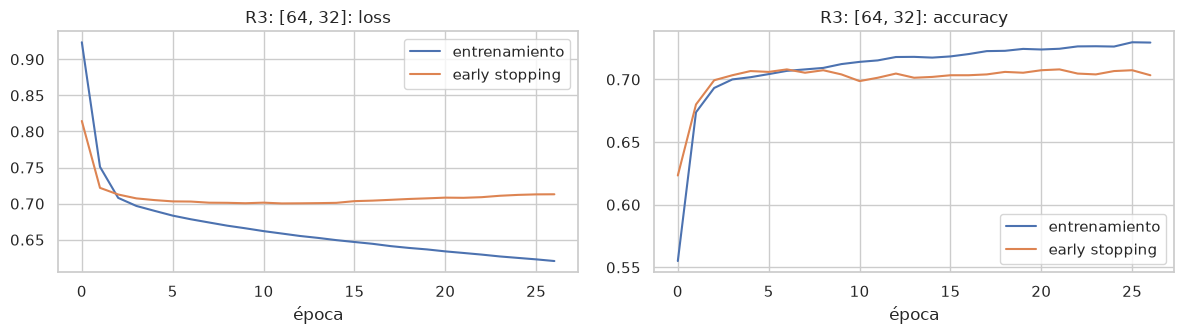

,experimento,capas,dropout,lr,batch,pesos,épocas,mejor_época,acc_ent,acc_val,f1_ent,f1_val
0,"R3: [64, 32]","[64, 32]",0.0,0.001,32,-,27,12,0.721,0.704,0.646,0.627


In [34]:
_, res = experimento_rna('R3: [64, 32]', [64, 32])
pd.DataFrame([res]).round(3)

## 5.5 Experimento 4: regularización con Dropout

Dropout apaga al azar una fracción de neuronas en cada paso de entrenamiento, lo que obliga a la red a no
depender de neuronas puntuales y reduce el sobreajuste.

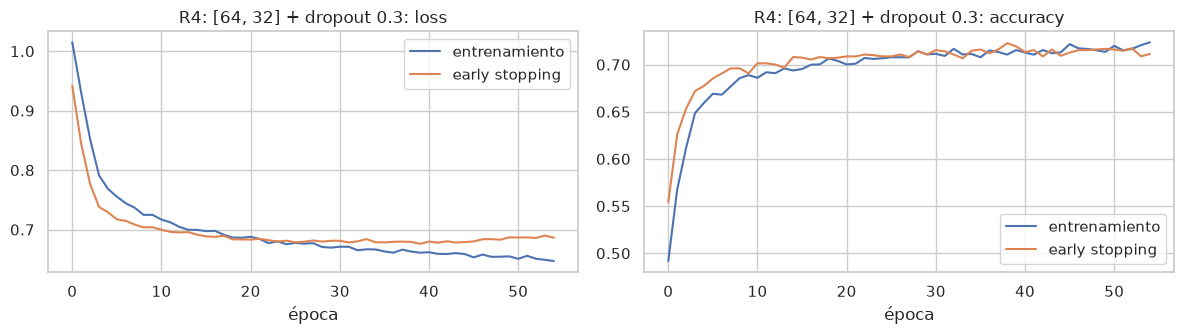

,experimento,capas,dropout,lr,batch,pesos,épocas,mejor_época,acc_ent,acc_val,f1_ent,f1_val
0,"R4: [64, 32] + dropout 0.3","[64, 32]",0.3,0.001,32,-,55,40,0.736,0.711,0.665,0.636


In [35]:
_, res = experimento_rna('R4: [64, 32] + dropout 0.3', [64, 32], dropout=0.3)
pd.DataFrame([res]).round(3)

## 5.6 Experimento 5: red más grande con Dropout

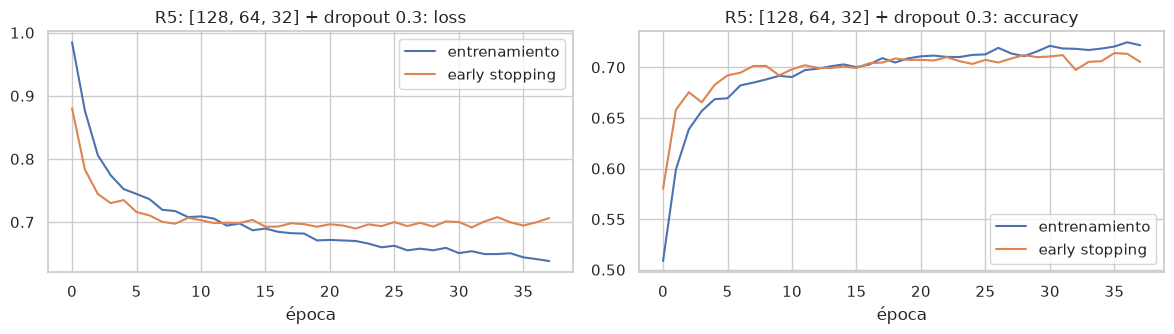

,experimento,capas,dropout,lr,batch,pesos,épocas,mejor_época,acc_ent,acc_val,f1_ent,f1_val
0,"R5: [128, 64, 32] + dropout 0.3","[128, 64, 32]",0.3,0.001,32,-,38,23,0.734,0.708,0.671,0.643


In [36]:
_, res = experimento_rna('R5: [128, 64, 32] + dropout 0.3', [128, 64, 32], dropout=0.3)
pd.DataFrame([res]).round(3)

## 5.7 Experimento 6: tasa de aprendizaje

La tasa de aprendizaje controla el tamaño de cada paso del descenso por gradiente: muy chica entrena
lento; muy grande puede oscilar sin converger.

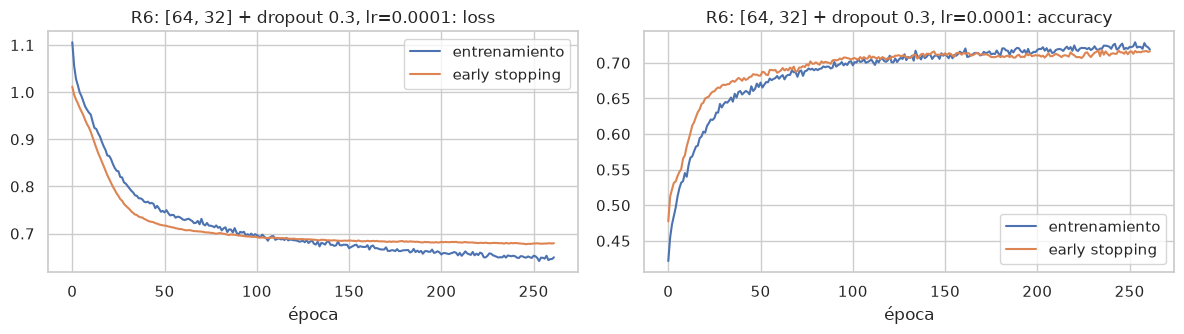

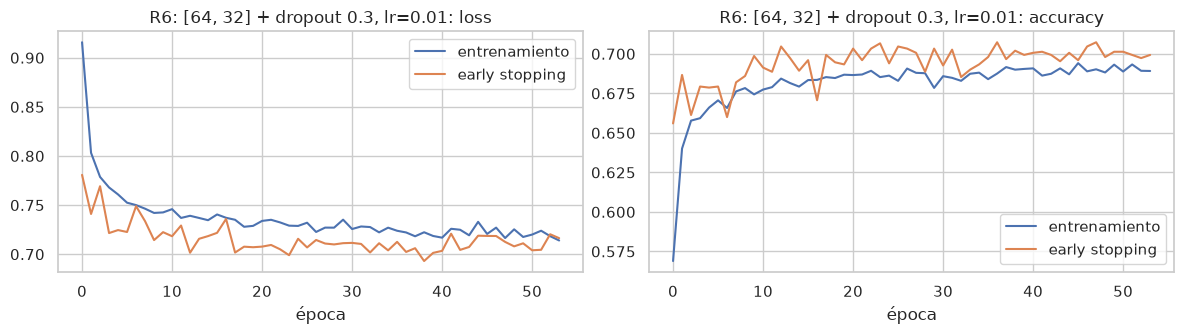

,experimento,capas,dropout,lr,batch,pesos,épocas,mejor_época,acc_ent,acc_val,f1_ent,f1_val
0,"R6: [64, 32] + dropout 0.3, lr=0.0001","[64, 32]",0.3,0.0001,32,-,262,247,0.740,0.708,0.670,0.628
1,"R6: [64, 32] + dropout 0.3, lr=0.01","[64, 32]",0.3,0.01,32,-,54,39,0.719,0.710,0.638,0.635


In [37]:
filas = []
for lr in [1e-4, 1e-2]:
    _, res = experimento_rna(f'R6: [64, 32] + dropout 0.3, lr={lr}', [64, 32], dropout=0.3, tasa_aprendizaje=lr)
    filas.append(res)
pd.DataFrame(filas).round(3)

## 5.8 Experimento 7: tamaño de batch

Un batch más grande da gradientes menos ruidosos y entrena más rápido por época, pero hace menos
actualizaciones de los pesos.

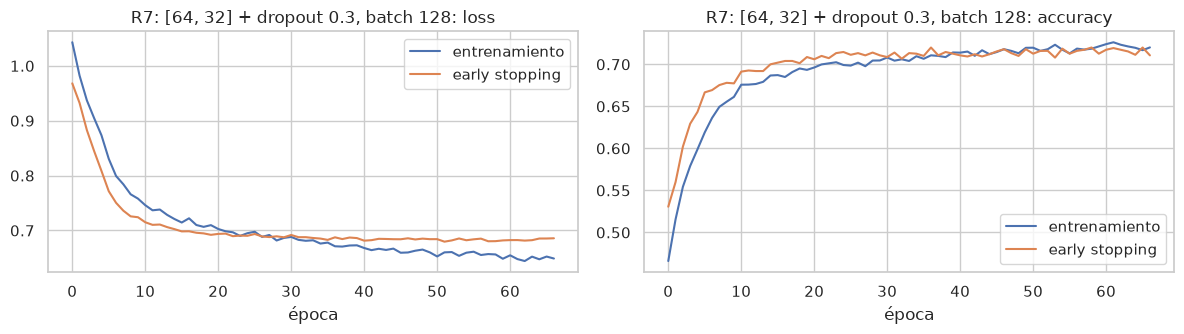

,experimento,capas,dropout,lr,batch,pesos,épocas,mejor_época,acc_ent,acc_val,f1_ent,f1_val
0,"R7: [64, 32] + dropout 0.3, batch 128","[64, 32]",0.3,0.001,128,-,67,52,0.736,0.713,0.659,0.635


In [38]:
_, res = experimento_rna('R7: [64, 32] + dropout 0.3, batch 128', [64, 32], dropout=0.3, batch_size=128)
pd.DataFrame([res]).round(3)

## 5.9 Experimento 8: pesos de clases

Como con el árbol, `class_weight` penaliza más los errores en las clases minoritarias.

{'Mala': np.float64(0.87), 'Buena': np.float64(0.72), 'Muy buena': np.float64(2.17)}


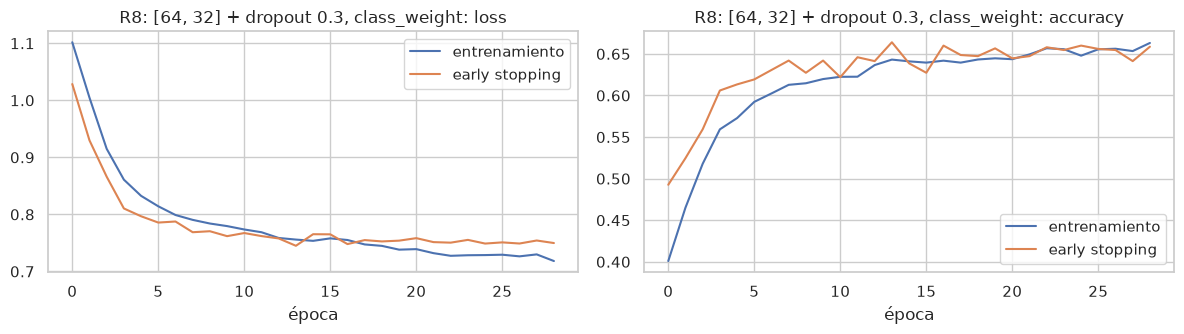

,experimento,capas,dropout,lr,batch,pesos,épocas,mejor_época,acc_ent,acc_val,f1_ent,f1_val
0,"R8: [64, 32] + dropout 0.3, class_weight","[64, 32]",0.3,0.001,32,balanced,29,14,0.665,0.647,0.638,0.616


In [39]:
from sklearn.utils.class_weight import compute_class_weight

def calcular_pesos(etiquetas):
    pesos = compute_class_weight('balanced', classes=np.array(orden_clases), y=etiquetas)
    return dict(enumerate(pesos))  # Keras identifica cada clase por su posición en el vector one-hot


pesos_clases = calcular_pesos(y_red)
print({orden_clases[k]: round(v, 2) for k, v in pesos_clases.items()})
_, res = experimento_rna('R8: [64, 32] + dropout 0.3, class_weight', [64, 32], dropout=0.3,
                         pesos_clases=pesos_clases)
pd.DataFrame([res]).round(3)

## 5.10 Resumen de experimentos de la red neuronal

In [40]:
resumen_rna = pd.DataFrame(experimentos_rna).round(3)
resumen_rna

,experimento,capas,dropout,lr,batch,pesos,épocas,mejor_época,acc_ent,acc_val,f1_ent,f1_val
0,"R1: [16], 200 épocas fijas",[16],0.0,0.001,32,-,200,200,0.730,0.708,0.668,0.633
1,R2: [16] + early stopping,[16],0.0,0.001,32,-,87,72,0.722,0.707,0.653,0.627
2,"R3: [64, 32]","[64, 32]",0.0,0.001,32,-,27,12,0.721,0.704,0.646,0.627
3,"R4: [64, 32] + dropout 0.3","[64, 32]",0.3,0.001,32,-,55,40,0.736,0.711,0.665,0.636
4,"R5: [128, 64, 32] + dropout 0.3","[128, 64, 32]",0.3,0.001,32,-,38,23,0.734,0.708,0.671,0.643
5,"R6: [64, 32] + dropout 0.3, lr=0.0001","[64, 32]",0.3,0.0001,32,-,262,247,0.740,0.708,0.670,0.628
6,"R6: [64, 32] + dropout 0.3, lr=0.01","[64, 32]",0.3,0.01,32,-,54,39,0.719,0.710,0.638,0.635
7,"R7: [64, 32] + dropout 0.3, batch 128","[64, 32]",0.3,0.001,128,-,67,52,0.736,0.713,0.659,0.635
8,"R8: [64, 32] + dropout 0.3, class_weight","[64, 32]",0.3,0.001,32,balanced,29,14,0.665,0.647,0.638,0.616


Lectura de la tabla, experimento por experimento.

Las diferencias entre R1 y R7 son chicas (F1 macro entre 0.627 y 0.643), así que conviene leerlas como
tendencias y no como mejoras firmes.

### R1: sin early stopping
La pérdida de early stopping llega a su mínimo en la época 72 y después sube levemente (0.693 → 0.699 en
la época 200) mientras la de entrenamiento sigue bajando: la red empieza a sobreajustar. F1 macro en
validación: 0.633.

### R2: early stopping
Corta en la época 87 (mejor época: 72) con un resultado equivalente (0.627) y menos de la mitad de las
épocas. Desde acá todos los experimentos usan early stopping.

### R3: más capacidad, [64, 32]
Sobreajusta mucho antes (la mejor época es la 12) y no mejora (0.627).

### R4: Dropout 0.3
La regularización deja entrenar más tiempo a la red grande (mejor época: 40) y mejora a R3 (0.636).

### R5: red más grande con Dropout
Tres capas ocultas con Dropout dan el **mejor resultado (0.643)**, aunque la mejora sobre R4 es chica.

### R6: tasa de aprendizaje
Variaciones de R4:
- 0.0001: tarda 262 épocas (mejor época: 247) y no mejora (0.628).
- 0.01: converge en menos épocas con un resultado similar (0.635).

### R7: batch 128
Variación de R4: resultado similar (0.635).

### R8: pesos de clases
Igual que en el árbol, empeora el F1 macro (0.616) y la accuracy (0.647).

### Elección
Se elige **R5**: tres capas ocultas de 128, 64 y 32 neuronas, Dropout 0.3, Adam con tasa 0.001, batch 32.

## 5.11 Evaluación de la mejor red

Mejor experimento: R5: [128, 64, 32] + dropout 0.3 | épocas para el modelo final: 23
              precision    recall  f1-score   support

        Mala      0.757     0.798     0.777       962
       Buena      0.683     0.758     0.718      1154
   Muy buena      0.626     0.331     0.433       384

    accuracy                          0.708      2500
   macro avg      0.688     0.629     0.643      2500
weighted avg      0.702     0.708     0.697      2500



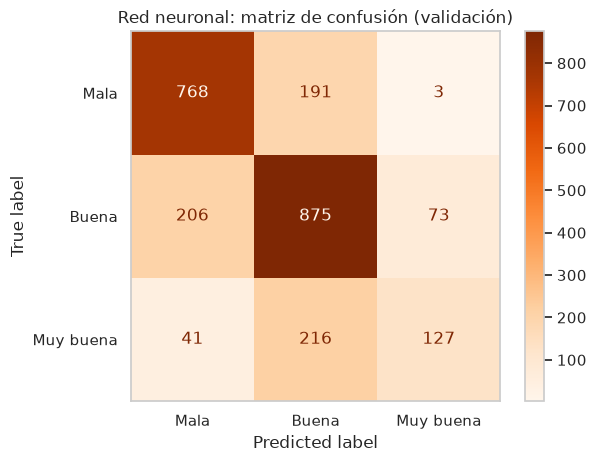

In [41]:
indice_mejor = resumen_rna['f1_val'].idxmax()
mejor_exp_rna = resumen_rna.loc[indice_mejor]
mejor_rna, config_rna = modelos_rna[indice_mejor]
epocas_finales_rna = int(mejor_exp_rna['mejor_época'])
print('Mejor experimento:', mejor_exp_rna['experimento'], '| épocas para el modelo final:', epocas_finales_rna)

pred_val_rna = a_etiquetas(mejor_rna.predict(Xr_val, verbose=0))
print(classification_report(y_val, pred_val_rna, labels=orden_clases, digits=3))
ConfusionMatrixDisplay.from_predictions(y_val, pred_val_rna, labels=orden_clases, cmap='Oranges')
plt.title('Red neuronal: matriz de confusión (validación)')
plt.grid(False)
plt.show()

# 6. Comparación de modelos

In [42]:
def metricas(y_real, y_pred):
    f1_clases = f1_score(y_real, y_pred, labels=orden_clases, average=None)
    return {'accuracy': accuracy_score(y_real, y_pred), 'f1_macro': f1_score(y_real, y_pred, average='macro'),
            **{f'f1_{c}': f for c, f in zip(orden_clases, f1_clases)}}

comparacion = pd.DataFrame({
    'Línea base': metricas(y_val, pred_base_val),
    'Árbol de decisión': metricas(y_val, pred_val_arbol),
    'Red neuronal': metricas(y_val, pred_val_rna),
}).T.round(3)
comparacion

,accuracy,f1_macro,f1_Mala,f1_Buena,f1_Muy buena
Línea base,0.462,0.211,0.000,0.632,0.000
Árbol de decisión,0.718,0.666,0.771,0.732,0.497
Red neuronal,0.708,0.643,0.777,0.718,0.433


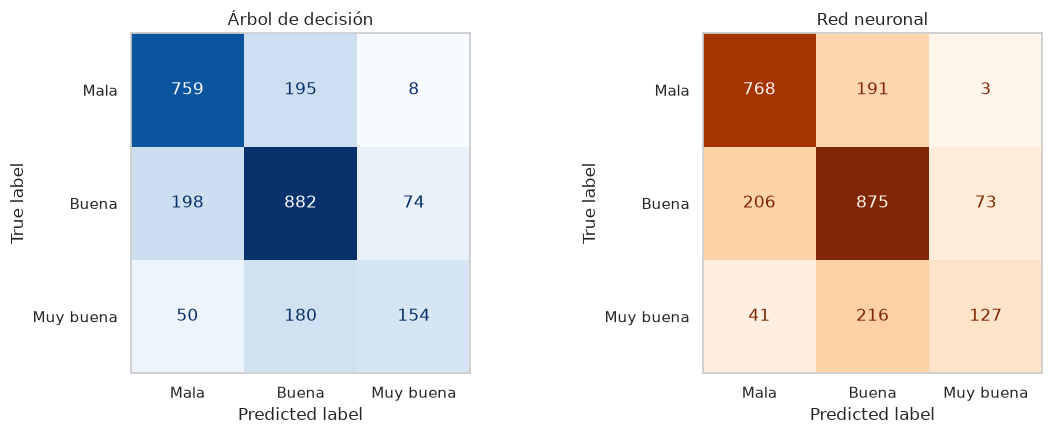

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_predictions(y_val, pred_val_arbol, labels=orden_clases, cmap='Blues',
                                        ax=axes[0], colorbar=False)
axes[0].set_title('Árbol de decisión')
ConfusionMatrixDisplay.from_predictions(y_val, pred_val_rna, labels=orden_clases, cmap='Oranges',
                                        ax=axes[1], colorbar=False)
axes[1].set_title('Red neuronal')
for ax in axes:
    ax.grid(False)
plt.tight_layout()
plt.show()

## 6.1 Conclusiones

### Ambos superan la línea base
El F1 macro pasa de 0.21 a ~0.65.

### El árbol queda por encima
El **árbol** supera a la **red** en validación (F1 macro 0.666 contra 0.643, accuracy 0.718 contra
0.708). La diferencia sale casi toda de *Muy buena* (F1 0.497 contra 0.433).

### *Muy buena* es la clase difícil
Los dos modelos aciertan bien *Mala* y *Buena*, pero **les cuesta *Muy buena***: el árbol encuentra el
40 % de esas películas y la red el 33 %. Es la clase minoritaria, y la mayoría de sus errores la
confunden con *Buena* (180 de 384 casos en el árbol, 216 en la red). Dar más peso a esa clase
(`class_weight`) no mejoró el F1 macro en ninguno de los dos modelos.

### La popularidad es el atributo clave
La **popularidad** de la película es por lejos el atributo más importante del árbol (importancia 0.54 y
primer corte), seguida por la popularidad de las películas de los intérpretes.

### Más capacidad ayudó poco
La red más grande fue la mejor, pero por muy poco: el límite parece estar en la información que tienen
los atributos más que en la capacidad del modelo.

### Interpretabilidad
El árbol tiene la ventaja de ser **interpretable** y de no requerir escalado; la red requiere más
preprocesamiento y más decisiones de ajuste (arquitectura, tasa de aprendizaje, épocas, regularización).

# 7. Predicciones sobre test

Con los hiperparámetros elegidos, cada modelo se **reentrena con todo el conjunto de train** (más datos
suelen dar un modelo algo mejor). El test pasa por el mismo preprocesamiento, ajustado solo con train.

- **Árbol:** mejores parámetros del barrido conjunto (experimento 5).
- **Red:** la mejor configuración, entrenada durante la cantidad de épocas que eligió el early stopping
  (ya no queda un conjunto aparte para monitorear).

In [44]:
X_test = crear_atributos(test.drop(columns='class'))

Xa_total, Xa_test = preprocesar(X, X_test)
arbol_final = DecisionTreeClassifier(random_state=SEMILLA, **mejores_params_arbol).fit(Xa_total, y)
pred_test_arbol = arbol_final.predict(Xa_test)

Xr_total, Xr_test = escalar(*preprocesar(X, X_test))
rna_final = construir_rna(config_rna['capas'], config_rna['dropout'], config_rna['tasa_aprendizaje'])
pesos_finales = calcular_pesos(y) if config_rna['pesos_clases'] else None
rna_final.fit(Xr_total, a_one_hot(y), epochs=epocas_finales_rna, batch_size=config_rna['batch_size'],
              class_weight=pesos_finales, verbose=0)
pred_test_rna = a_etiquetas(rna_final.predict(Xr_test, verbose=0))

In [45]:
predicciones = test.copy()
predicciones['pred_arbol'] = pred_test_arbol
predicciones['pred_rna'] = pred_test_rna

assert len(predicciones) == len(test)
assert (predicciones['movieId'] == test['movieId']).all()
predicciones.to_csv('claude-predicciones_test.csv', index=False)

print('Guardado claude-predicciones_test.csv:', predicciones.shape)
predicciones[['title', 'pred_arbol', 'pred_rna']].head()

Guardado claude-predicciones_test.csv: (500, 27)


,title,pred_arbol,pred_rna
0,Captive Wild Woman (1943),Mala,Mala
1,Les disparus de Saint-Agil (1938),Buena,Buena
2,"Trotsky, The (2009)",Buena,Buena
3,"Late Mathias Pascal, The (a.k.a. The Living De...",Buena,Buena
4,He's Mine Not Yours (2011),Mala,Mala


In [46]:
pd.DataFrame({'árbol': predicciones['pred_arbol'].value_counts(normalize=True),
              'red': predicciones['pred_rna'].value_counts(normalize=True)}).reindex(orden_clases).round(3)

,árbol,red
Mala,0.384,0.448
Buena,0.546,0.514
Muy buena,0.070,0.038


## 7.1 Control final con la clase del test (solo informativo)

El archivo de test incluye la columna `class`. No se usó para ninguna decisión; se evalúa una única vez
al final como estimación del desempeño sobre datos nunca vistos. **Conviene confirmar con la cátedra si
corresponde mostrarlo.**

In [47]:
pd.DataFrame({
    'Árbol de decisión': metricas(test['class'], predicciones['pred_arbol']),
    'Red neuronal': metricas(test['class'], predicciones['pred_rna']),
}).T.round(3)

,accuracy,f1_macro,f1_Mala,f1_Buena,f1_Muy buena
Árbol de decisión,0.682,0.638,0.719,0.694,0.500
Red neuronal,0.686,0.589,0.755,0.701,0.312


El test confirma el orden de validación en F1 macro: el árbol (0.638) supera a la red (0.589), con
accuracy casi igual (0.682 y 0.686). La red predice *Muy buena* para muy pocas películas del test (4 %,
contra un 15 % real), y por eso su F1 en esa clase es bajo. Este resultado **no** se usa para cambiar los
modelos elegidos: hacerlo sería ajustar decisiones con el test.

# 8. Uso de herramientas de IA

Este notebook de referencia fue generado íntegramente por **Claude** (asistente de IA de Anthropic,
mediante Claude Code): análisis exploratorio, preprocesamiento, experimentos, comparación y generación
de predicciones, junto con los textos explicativos.